# 286: Can kmerseek reach BCL2 from Ced9 through a human protein in between?

PSI-BLAST and jackhmmer find distant homologs by searching again with what the first
search found: if Ced9 finds MCL1, and MCL1 finds BCL2, then Ced9 reaches BCL2 through MCL1
(a path through an intermediate sequence). This notebook asks whether kmerseek can do the
same, and whether the path it finds is better than chance.

**Background** ([notebook 284](284_alphabet_agreement_explainer.html),
[PR 125](https://github.com/seanome/2024-kmerseek-analysis/pull/125),
`284_ced9_bcl2_family_hits.csv`). Against the human proteome, kmerseek finds MCL1 from
Ced9 at E = 16.7 (dayhoff6, k = 12: Ced9 168-185 on MCL1 261-278, the BH1 motif, 10 of 18
residues identical) and BAK1 at E = 23.9 (dayhoff6, k = 11, BH1). Its best region on BCL2
has E = 1_955, and 12_894 human genes have a better one. The E-value is the number of
regions this good expected by chance in the whole search, so lower is better and E above
about 1 is what chance gives.

**Decision this informs.** Whether kmerseek needs a two-step search mode (search again with
each hit, keep the paths) to reach BCL2 from Ced9, and whether the paper can say kmerseek
reaches BCL2 that way. If the rule below passes, the two-step mode is worth building and the
BCL2 case gets a path figure. If it fails, the paper says BCL2 stays out of kmerseek's reach
from Ced9 even through human proteins, and the two-step mode is not built for this case.

**Data.** Queries: Ced9 (*C. elegans* CED-9, 280 aa) and P66 (*Borrelia* P66, the second
case of notebook 241), each with 20 dipeptide-shuffled copies (notebook 284's copies, made
by `284_shuffle_agreement.py` with seed 284: each copy keeps the query's length, first and
last residue and the count of every adjacent residue pair, so it has the query's
composition and no homology). Target database: 19_732 GENCODE v49 canonical human proteins.
kmerseek 0.4.0 at commit 982a055 with notebook 241's 152 settings (a setting is one of 19
alphabets at one k-mer size, scaled 1, low-complexity mask on, notebook 241's extension),
indexes and search flags. Run on Sherlock with `286_intermediate_sequence.sbatch`.

**Method.**
1. Step 1: each query against the human proteome. Every human protein X with a region at
   E < 100 at any setting is an intermediate. Notebook 241 already did this for Ced9 and
   P66; the run repeats it for them (and must match 241 exactly) and does it for the copies.
2. Step 2: every human protein against the human proteome, at the same settings. A region
   X → Y with E < 100 at any setting continues the path. The whole proteome is searched
   because the 42 sets of intermediates together cover nearly all of it.
3. A path query → X → Y counts only when the query's stretch on X and the X stretch that
   hits Y share at least one residue of X. Its score is the larger of its two E-values: a
   path is as weak as its weaker step. Each human gene Y keeps its best path, and the genes
   reached are ranked by that score (rank 1 is best; ties share the best rank).
4. The same for each shuffled copy. How often a copy reaches BCL2 (or CD47) at a rank as
   good as the real query's says how often chance alone does it.

**Which intermediates.** Every human protein with E < 100, not the top N by E-value: in
notebook 284's table MCL1 is Ced9's 321st best human gene and BAK1 its 468th, so a top-20
rule would leave both out. This was known from PR 125 before the rule was chosen.

**Decision rule, written 2026-10-13 before any step 2 search.** Ced9 reaches BCL2 through
an intermediate when all three hold:
1. BCL2 is among the 10 best genes reached (its rank, counting tied genes as ahead of it,
   is 10 or better);
2. the stretch the two steps share on the intermediate lies in the intermediate's BH1 or
   BH4 motif (UniProt, as in notebook 284);
3. no more than 0 of the 20 shuffled copies reaches BCL2 at a rank as good, so that
   (1 + copies as good) / 21 is at most 0.05.

P66 reaches CD47 when 1 and 3 hold for CD47 (no motif annotation plays the part of BH1).

**Prediction, written before the run.** Rule 1 fails for Ced9. A path's score can be no
better than its first step, so a path through MCL1 scores 16.7 or worse, while section 1
shows how many human proteins Ced9 reaches directly at a lower E. Each of those passes its
own strong homologs on at about its own E, and those genes rank ahead of BCL2. Rule 3, the
comparison with the copies, can still pass, and is the part of the answer that does not
depend on where the line of 10 sits.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf
from residue_pair_utils import ungapped_pair_text

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_tbl_cols(30)
pl.Config.set_fmt_str_lengths(60)

DATA = Path.home() / "data/botryllus/alphabet-ranking-three-cases"
# copied back from Sherlock: results/, pilot.jsonl, step2_plan.csv
RUN = Path(os.environ.get("NB286_RUN", DATA / "286"))
HUMAN = Path.home() / "data/gencode/human/v49/gencode.v49.pc_translations.canonical.fa"
FIG = Path("../figures")
E_INCLUDE = 100.0
N_SHUFFLES = 20
TOP_N_RULE = 10
PARTNERS = {"Ced9": "BCL2", "P66": "CD47"}
BCL2_FAMILY = [
    "BCL2",
    "BCL2L1",
    "BCL2L2",
    "MCL1",
    "BCL2A1",
    "BCL2L10",
    "BAK1",
    "BAX",
    "BOK",
]
# UniProt BH motifs, 1-based inclusive, as in notebook 284 (scripts/284_ced9_bcl2_family_hits.py)
MOTIFS = {
    "BCL2": {"BH4": (10, 30), "BH3": (93, 107), "BH1": (136, 155), "BH2": (187, 202)},
    "BCL2L1": {"BH4": (4, 24), "BH3": (86, 100), "BH1": (129, 148), "BH2": (180, 195)},
    "MCL1": {"BH3": (209, 223), "BH1": (252, 272), "BH2": (304, 319)},
    "BAK1": {"BH3": (74, 88), "BH1": (117, 136), "BH2": (169, 184)},
    "BAX": {"BH3": (59, 73), "BH1": (98, 118), "BH2": (150, 165)},
}
TOOLS = (
    "kmerseek 0.4.0 (982a055), notebook 241's 152 settings; query Ced9 or P66; "
    "target database 19_732 GENCODE v49 canonical human proteins"
)


# Column types of 286_partner_rank.csv: a column that is empty for every query (no query
# reaches its partner) would otherwise be read as text.
PARTNER_RANK_TYPES = (
    {
        c: pl.Int64
        for c in [
            "n_intermediates",
            "n_genes_reached",
            "rank",
            "n_tied",
            "q_start",
            "q_end",
            "x1_start",
            "x1_end",
            "x2_start",
            "x2_end",
            "y_start",
            "y_end",
            "overlap",
        ]
    }
    | {c: pl.Float64 for c in ["direct_best_e", "score", "e1", "e2"]}
    | {c: pl.String for c in ["x_gene", "setting1", "setting2", "partner_motifs"]}
)


def read_fasta(p):
    out, name = {}, None
    for line in open(p):
        if line.startswith(">"):
            name = line[1:].split()[0]
            out[name] = ""
        else:
            out[name] += line.strip()
    return out


QUERIES = read_fasta(DATA / "queries.fa")
HUMAN_SEQ = read_fasta(HUMAN)
GENE_OF = {h: h.split("|")[6] for h in HUMAN_SEQ}
print(
    f"{len(HUMAN_SEQ)} human proteins, {len(set(GENE_OF.values()))} gene symbols; "
    f"Ced9 {len(QUERIES['Ced9'])} aa, P66 {len(QUERIES['P66'])} aa"
)

19732 human proteins, 19705 gene symbols; Ced9 280 aa, P66 597 aa


## 1. Step 1, from notebook 241: the human proteins Ced9 and P66 reach

Each human protein's best region from Ced9 (or P66) over all 152 settings, from notebook
241's `regions.parquet`. A protein with E < 100 is an intermediate. The figure ranks every
human protein by that E-value; read across from E = 100 to see how many intermediates each
query has, and up from a BCL-2 family member to see its E-value.

In [2]:
best = (
    pl.scan_parquet(DATA / "regions.parquet")
    .filter(
        pl.col("query_name").is_in(list(PARTNERS)) & pl.col("region_evalue").is_finite()
    )
    .sort("region_evalue", "alphabet", "ksize_arm", "region_start")
    .group_by("query_name", "target_name", maintain_order=True)
    .first()
    .with_columns(
        rank=pl.col("region_evalue").rank("min").over("query_name").cast(pl.Int32)
    )
    .sort("query_name", "rank")
    .collect()
)
assert (
    best["region_end"] - best["region_start"]
    == best["target_end"] - best["target_start"]
).all()
mcl1_e = best.filter((pl.col("query_name") == "Ced9") & (pl.col("gene") == "MCL1"))[
    "region_evalue"
].min()
counts = (
    best.group_by("query_name")
    .agg(
        human_proteins_with_a_region=pl.len(),
        e_below_1=(pl.col("region_evalue") < 1).sum(),
        e_below_10=(pl.col("region_evalue") < 10).sum(),
        e_below_mcl1=(pl.col("region_evalue") < mcl1_e).sum(),
        intermediates_e_below_100=(pl.col("region_evalue") < E_INCLUDE).sum(),
    )
    .sort("query_name")
)
print(
    f"Human proteins each query reaches in step 1 (best region over 152 settings); "
    f"e_below_mcl1 is E < {mcl1_e:.1f}, Ced9's best E on MCL1:"
)
print(counts)
named = (
    best.filter(pl.col("gene").is_in(BCL2_FAMILY + ["CD47"]))
    .select(
        "query_name",
        "gene",
        "rank",
        "region_evalue",
        "alphabet",
        "ksize_arm",
        q_start=pl.col("region_start") + 1,
        q_end="region_end",
        t_start=pl.col("target_start") + 1,
        t_end="target_end",
    )
    .sort("query_name", "rank")
)
print("\nBCL-2 family members and CD47 in step 1 (coordinates 1-based, inclusive):")
print(named)
out = best.filter(pl.col("region_evalue") < E_INCLUDE).select(
    "query_name",
    "gene",
    ensp=pl.col("target_name").str.split("|").list.get(0),
    rank="rank",
    best_evalue="region_evalue",
    alphabet="alphabet",
    k="ksize_arm",
    q_start=pl.col("region_start") + 1,
    q_end="region_end",
    t_start=pl.col("target_start") + 1,
    t_end="target_end",
)
out.write_csv("286_step1_intermediates_from_241.csv")
print(f"\nwrote 286_step1_intermediates_from_241.csv: {out.height} rows")

Human proteins each query reaches in step 1 (best region over 152 settings); e_below_mcl1 is E < 16.7, Ced9's best E on MCL1:
shape: (2, 6)
┌────────────┬──────────────────────────────┬───────────┬────────────┬──────────────┬───────────────────────────┐
│ query_name ┆ human_proteins_with_a_region ┆ e_below_1 ┆ e_below_10 ┆ e_below_mcl1 ┆ intermediates_e_below_100 │
│ ---        ┆ ---                          ┆ ---       ┆ ---        ┆ ---          ┆ ---                       │
│ str        ┆ u32                          ┆ u32       ┆ u32        ┆ u32          ┆ u32                       │
╞════════════╪══════════════════════════════╪═══════════╪════════════╪══════════════╪═══════════════════════════╡
│ Ced9       ┆ 19103                        ┆ 9         ┆ 170        ┆ 320          ┆ 2059                      │
│ P66        ┆ 19565                        ┆ 3         ┆ 124        ┆ 232          ┆ 1769                      │
└────────────┴──────────────────────────────┴───────────┴─────

Both axes are spaced by ratio: the step from 1 to 10 takes as much room as 10 to 100.


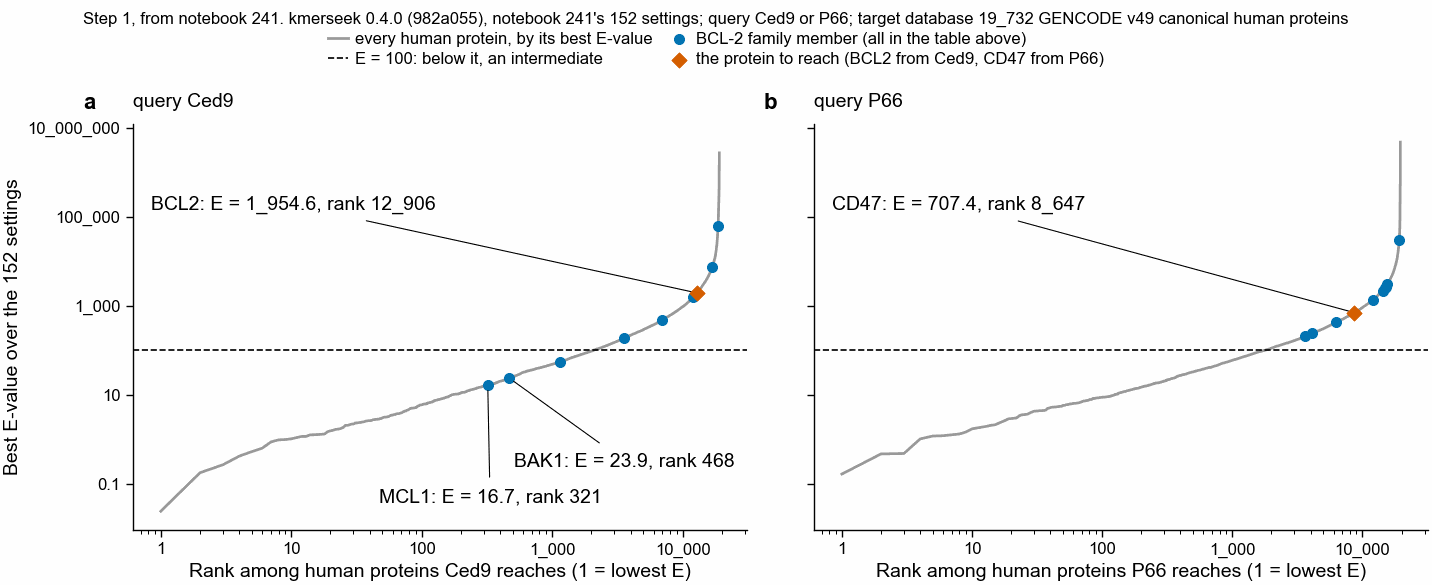

In [3]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 75, ncols=2, sharey=True)
c_rest, c_family, c_partner = pf.GREY, pf.OKABE_ITO["blue"], pf.OKABE_ITO["vermillion"]
# Label positions in axes fraction, chosen so no leader line crosses a label: the BCL2 and
# CD47 labels sit in the empty upper left, MCL1's and BAK1's under the curve below their points.
LABELLED = {
    "Ced9": {"MCL1": (0.40, 0.08), "BAK1": (0.62, 0.17), "BCL2": (0.03, 0.80)},
    "P66": {"CD47": (0.03, 0.80)},
}
for ax, q, letter in zip(axs, PARTNERS, "ab"):
    d = best.filter(pl.col("query_name") == q)
    ax.plot(
        d["rank"],
        d["region_evalue"],
        color=c_rest,
        label="every human protein, by its best E-value",
    )
    ax.axhline(
        E_INCLUDE,
        color="black",
        ls="--",
        lw=0.6,
        label=f"E = {E_INCLUDE:g}: below it, an intermediate",
    )
    fam = d.filter(pl.col("gene").is_in(BCL2_FAMILY) & (pl.col("gene") != PARTNERS[q]))
    ax.scatter(
        fam["rank"],
        fam["region_evalue"],
        color=c_family,
        s=12,
        zorder=3,
        label="BCL-2 family member (all in the table above)",
    )
    p = d.filter(pl.col("gene") == PARTNERS[q])
    ax.scatter(
        p["rank"],
        p["region_evalue"],
        color=c_partner,
        marker="D",
        s=14,
        zorder=4,
        label="the protein to reach (BCL2 from Ced9, CD47 from P66)",
    )
    for gene, xy in LABELLED[q].items():
        row = d.filter(pl.col("gene") == gene).row(0, named=True)
        ax.annotate(
            f"{gene}: E = {row['region_evalue']:_.1f}, rank {row['rank']:_}",
            (row["rank"], row["region_evalue"]),
            xytext=xy,
            textcoords="axes fraction",
            ha="left",
            va="center",
            arrowprops=dict(arrowstyle="-", lw=0.4, color="black"),
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"Rank among human proteins {q} reaches (1 = lowest E)")
    ax.set_title(f"query {q}", loc="left")
    pf.panel_label(ax, letter)
axs[0].set_ylabel("Best E-value over the 152 settings")
plain = plt.FuncFormatter(lambda v, _: f"{v:_.0f}" if v >= 1 else f"{v:g}")
for ax in axs:
    ax.xaxis.set_major_formatter(plain)
    ax.yaxis.set_major_formatter(plain)
pf.shared_legend(fig, ncol=2, title="Step 1, from notebook 241. " + TOOLS)
pf.save(fig, FIG / "286_step1_evalue_by_rank_Ced9_P66_human_gencode")
print(
    "Both axes are spaced by ratio: the step from 1 to 10 takes as much room as 10 to 100."
)

## 2. The residues behind the step-1 regions

Each region is ungapped: the query's residues line up one to one with the human protein's.
Under the residues, the same stretch in the alphabet that found it, each residue written as
the first residue of its class, with its own match line.

In [4]:
def show_best(q, gene):
    d = best.filter((pl.col("query_name") == q) & (pl.col("gene") == gene))
    if d.height == 0:
        print(f"{q} has no region on {gene}\n")
        return
    r = d.row(0, named=True)
    n = int(r["region_end"] - r["region_start"])
    print(
        f"{q} on {gene}: E = {r['region_evalue']:.3g}, {r['alphabet']} k = {r['ksize_arm']}, "
        f"rank {r['rank']:_} of {best.filter(pl.col('query_name') == q).height:_}"
    )
    print(
        ungapped_pair_text(
            q,
            QUERIES[q],
            int(r["region_start"]),
            gene,
            HUMAN_SEQ[r["target_name"]],
            int(r["target_start"]),
            n,
            r["alphabet"],
        )
    )
    print()


for gene in ["MCL1", "BAK1", "BCL2"]:
    show_best("Ced9", gene)
show_best("P66", "CD47")
for q in PARTNERS:
    print(f"--- {q}'s three best human proteins in step 1 ---")
    for gene in best.filter(pl.col("query_name") == q).sort("rank")["gene"].head(3):
        show_best(q, gene)

Ced9 on MCL1: E = 16.7, dayhoff6 k = 12, rank 321 of 19_103
Ced9 168-185 YGRLIGLISFGGFVAAKM
              ||   ||||| |||   
MCL1 261-278 WGRIVTLISFGAFVAKHL
10 of 18 residues identical
dayhoff6 classes: C AGPST DENQ FWY HKR ILMV (each written as its first residue)
Ced9         FAHIIAIIAFAAFIAAHI
             ||||||||||||||| ||
MCL1         FAHIIAIIAFAAFIAHHI
17 of 18 positions in the same dayhoff6 class

Ced9 on BAK1: E = 23.9, dayhoff6 k = 11, rank 468 of 19_103
Ced9 163-187 QCPMSYGRLIGLISFGGFVAAKMME
                   ||   |  ||   |     
BAK1 120-144 ESGINWGRVVALLGFGYRLALHVYQ
6 of 25 residues identical
dayhoff6 classes: C AGPST DENQ FWY HKR ILMV (each written as its first residue)
Ced9         DCAIAFAHIIAIIAFAAFIAAHIID
             | || |||||||||||  || || |
BAK1         DAAIDFAHIIAIIAFAFHIAIHIFD
19 of 25 positions in the same dayhoff6 class

Ced9 on BCL2: E = 1.95e+03, wwmj5 k = 9, rank 12_906 of 19_103
Ced9 78-99 LDIEGFVVDYFTHRIRQNGMEW
            |    |  |      | | ||
BCL2  9-30 YDN

## 3. The Sherlock run

`286_intermediate_sequence.sbatch` runs step 1 for the 42 queries, checks that Ced9's and
P66's E-values equal notebook 241's, runs step 2 on a pilot sample (150 random human
proteins and the 3 longest) to measure time and memory per setting, and submits step 2 for
the whole proteome sized from that pilot. The tables below appear once the run's small
tables are copied back to `~/data/botryllus/alphabet-ranking-three-cases/286/`.

In [5]:
plan_csv = RUN / "step2_plan.csv"
if not plan_csv.exists():
    print(f"not run yet: {plan_csv} is missing")
else:
    plan = pl.read_csv(plan_csv).sort("bits")
    print(
        plan.select(
            "setting",
            "bits",
            "pilot_max_rss_gb",
            "pilot_failed",
            "pred_hours",
            "ask_hours",
            "ask_mem_gb",
        )
    )
    fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2)
    axs[0].scatter(
        plan["bits"],
        plan["pred_hours"],
        color=pf.OKABE_ITO["blue"],
        s=8,
        label="one setting",
    )
    axs[0].set_xlabel("Seed bits of the setting (k-mer size x bits per letter)")
    axs[0].set_ylabel("Predicted hours, whole proteome")
    axs[1].scatter(
        plan["bits"], plan["pilot_max_rss_gb"], color=pf.OKABE_ITO["blue"], s=8
    )
    axs[1].set_xlabel("Seed bits of the setting (k-mer size x bits per letter)")
    axs[1].set_ylabel("Largest pilot process (GB)")
    for ax, letter in zip(axs, "ab"):
        pf.panel_label(ax, letter)
    pf.shared_legend(fig, title="Step 2 sizing, from the pilot. " + TOOLS)
    pf.save(fig, FIG / "286_step2_pilot_sizing_human_gencode")

not run yet: /Users/olga/data/botryllus/alphabet-ranking-three-cases/286/step2_plan.csv is missing


## 4. Does Ced9 reach BCL2, and P66 reach CD47, better than their shuffled copies?

For each query and copy: the rank of the partner (BCL2 or CD47) among the human genes
reached through an intermediate, ranked by path score (the larger of the path's two
E-values; lower is better). The decision rule from the top is applied by the code below.

In [6]:
pr_csv = RUN / "results" / "286_partner_rank.csv"
if not pr_csv.exists():
    print(f"not run yet: {pr_csv} is missing")
else:
    pr = pl.read_csv(pr_csv, schema_overrides=PARTNER_RANK_TYPES).with_columns(
        rank_with_ties=pl.col("rank") + pl.col("n_tied")
    )
    print(
        pr.select(
            "query_name",
            "partner",
            "n_intermediates",
            "n_genes_reached",
            "reached",
            "rank",
            "n_tied",
            "score",
            "e1",
            "e2",
            "x_gene",
            "setting1",
            "setting2",
            "direct_best_e",
        )
    )
    verdict = []
    for case, partner in PARTNERS.items():
        real = pr.filter(pl.col("query_name") == case).row(0, named=True)
        copies = pr.filter((pl.col("case") == case) & ~pl.col("real"))
        assert copies.height == N_SHUFFLES, copies.height
        if real["reached"]:
            as_good = copies.filter(
                pl.col("reached") & (pl.col("rank") <= real["rank"])
            ).height
            rule1 = real["rank_with_ties"] <= TOP_N_RULE
        else:
            as_good, rule1 = N_SHUFFLES, False
        p = (1 + as_good) / (1 + N_SHUFFLES)
        rule2 = None
        if case == "Ced9" and real["reached"]:
            lo, hi = max(real["x1_start"], real["x2_start"]) + 1, min(
                real["x1_end"], real["x2_end"]
            )
            m = MOTIFS.get(real["x_gene"], {})
            rule2 = any(
                lo <= b and hi >= a
                for name, (a, b) in m.items()
                if name in ("BH1", "BH4")
            )
        verdict.append(
            dict(
                query=case,
                partner=partner,
                reached=real["reached"],
                rank=real["rank"],
                rank_with_ties=real["rank_with_ties"],
                copies_as_good=as_good,
                p=p,
                rule1_top10=rule1,
                rule2_bh1_or_bh4=rule2,
                rule3_p_le_005=p <= 0.05,
                passes=rule1 and p <= 0.05 and (rule2 if case == "Ced9" else True),
            )
        )
    verdict = pl.DataFrame(verdict)
    print("\nDecision rule:")
    print(verdict)
    verdict.write_csv("286_decision.csv")

    fig, axs = pf.figure(pf.TWO_COLUMN_MM, 65, ncols=2)
    rng = np.random.default_rng(286)
    for ax, (case, partner), letter in zip(axs, PARTNERS.items(), "ab"):
        d = pr.filter(pl.col("case") == case)
        top = max(d["n_genes_reached"].max(), 10) * 2
        cop = d.filter(~pl.col("real"))
        x = rng.uniform(-0.15, 0.15, cop.height)
        y = np.where(cop["reached"], cop["rank"].fill_null(0), top)
        reached = cop["reached"].to_numpy()
        ax.scatter(x[reached], y[reached], color=pf.GREY, s=10)
        ax.scatter(x[~reached], y[~reached], color=pf.GREY, marker="x", s=10)
        real = d.filter(pl.col("real")).row(0, named=True)
        ax.scatter(
            [1],
            [real["rank"] if real["reached"] else top],
            color=pf.OKABE_ITO["vermillion"],
            marker="o" if real["reached"] else "x",
            s=16,
        )
        ax.axhline(TOP_N_RULE, color="black", ls="--", lw=0.6)
        ax.set_yscale("log")
        ax.set_ylim(top * 1.5, 0.8)
        ax.set_xticks([0, 1], [f"{N_SHUFFLES} shuffled copies of {case}", case])
        ax.set_xlim(-0.6, 1.6)
        ax.set_ylabel(f"Rank of {partner} among genes reached (1 = best)")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:_.0f}"))
        ax.set_title(f"{case} to {partner}", loc="left")
        pf.panel_label(ax, letter)
    from matplotlib.lines import Line2D

    proxies = [
        Line2D(
            [],
            [],
            ls="",
            marker="o",
            color=pf.OKABE_ITO["vermillion"],
            label="real query",
        ),
        Line2D([], [], ls="", marker="o", color=pf.GREY, label="shuffled copy"),
        Line2D(
            [],
            [],
            ls="",
            marker="o",
            color="black",
            label="dot: partner reached, at its rank",
        ),
        Line2D(
            [],
            [],
            ls="",
            marker="x",
            color="black",
            label="cross: partner not reached (bottom)",
        ),
        Line2D(
            [],
            [],
            ls="--",
            color="black",
            lw=0.6,
            label=f"rank {TOP_N_RULE}: the decision line",
        ),
    ]
    fig.legend(
        handles=proxies,
        loc="outside upper center",
        ncol=5,
        title="Two-step search; path score = the larger E-value of its two steps. "
        + TOOLS,
    )
    pf.save(
        fig, FIG / "286_partner_rank_real_vs_shuffled_Ced9-BCL2_P66-CD47_human_gencode"
    )
    print(
        "The rank axis is spaced by ratio: the step from 1 to 10 takes as much room as 10 to 100."
    )

not run yet: /Users/olga/data/botryllus/alphabet-ranking-three-cases/286/results/286_partner_rank.csv is missing


## 5. The best paths, in residues

For each real query, its best path to the partner and to its three best genes overall:
step 1 (query on the intermediate) and step 2 (intermediate on the gene reached), with the
residues of both and the residues of the intermediate they share.

In [7]:
top_csv = RUN / "results" / "286_real_top100_paths.csv"
if not top_csv.exists():
    print(f"not run yet: {top_csv} is missing")
else:
    top = pl.read_csv(top_csv)
    pr = pl.read_csv(
        RUN / "results" / "286_partner_rank.csv", schema_overrides=PARTNER_RANK_TYPES
    )

    def show_path(q, r):
        x_seq, y_seq = HUMAN_SEQ[r["x"]], HUMAN_SEQ[r["y"]]
        print(
            f"{q} -> {r['x_gene']} -> {r['y_gene']}: score {r['score']:.3g} "
            f"(step 1 E = {r['e1']:.3g}, {r['alphabet1']} k = {r['k1']}; "
            f"step 2 E = {r['e2']:.3g}, {r['alphabet2']} k = {r['k2']}); "
            f"residues of {r['x_gene']} in both steps: {r['overlap']}"
        )
        print(
            ungapped_pair_text(
                q,
                QUERIES[q],
                r["q_start"],
                r["x_gene"],
                x_seq,
                r["x1_start"],
                r["q_end"] - r["q_start"],
                r["alphabet1"],
            )
        )
        print(
            ungapped_pair_text(
                r["x_gene"],
                x_seq,
                r["x2_start"],
                r["y_gene"],
                y_seq,
                r["y_start"],
                r["x2_end"] - r["x2_start"],
                r["alphabet2"],
            )
        )
        print()

    for q, partner in PARTNERS.items():
        t = top.filter(pl.col("query_name") == q).sort("rank")
        print(f"=== {q}: ten best genes reached ===")
        print(t.select("rank", "y_gene", "x_gene", "score", "e1", "e2").head(10))
        for r in t.head(3).iter_rows(named=True):
            show_path(q, r)
        p = top.filter((pl.col("query_name") == q) & (pl.col("y_gene") == partner))
        if p.height:
            show_path(q, p.row(0, named=True))
        else:
            print(
                f"{partner} is not among {q}'s 100 best genes; its path is in 286_partner_rank.csv\n"
            )

not run yet: /Users/olga/data/botryllus/alphabet-ranking-three-cases/286/results/286_real_top100_paths.csv is missing


## 6. Summary

Waiting for the Sherlock run (sections 3-5). Sections 1 and 2 come from notebook 241's
search and do not depend on it.